### Import Library & Load Data

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

X_train, X_test, y_train, y_test, scaler = joblib.load('../dataset/data_hasil_preprocessing.pkl')
print(f"Data berhasil dimuat! Training: {len(X_train)} | Testing: {len(X_test)}")

Data berhasil dimuat! Training: 6053 | Testing: 1514


### Fungsi Perhitungan 6 Metrik Evaluasi

In [29]:
def hitung_metrik_jurnal(y_aktual, y_prediksi, jumlah_fitur=7):
    n = len(y_aktual)
    r2   = r2_score(y_aktual, y_prediksi)
    mae  = mean_absolute_error(y_aktual, y_prediksi)
    mse  = mean_squared_error(y_aktual, y_prediksi)
    rmse = np.sqrt(mse)
    mape = mean_absolute_percentage_error(y_aktual, y_prediksi)
    adj_r2 = 1 - ((1 - r2) * (n - 1) / (n - jumlah_fitur - 1))
    
    return {
        'R2': round(r2, 3),
        'Mean absolute error': round(mae, 3),
        'Mean squared error': round(mse, 3),
        'Root mean squared error': round(rmse, 3),
        'Mean absolute percentage error': round(mape, 3),
        'Adjusted R2': round(adj_r2, 3)
    }

### Pengujian Model Linear Regression (10 K-Fold CV & Testing)

In [30]:
model_lr = LinearRegression()

# Validasi pada Data Training menggunakan 10 K-Fold Cross-Validation
kf = KFold(n_splits=10, shuffle=True, random_state=42)
y_pred_train_lr = cross_val_predict(model_lr, X_train, y_train, cv=kf)

# Melatih model pada Data Training dan menguji pada Data Testing
model_lr.fit(X_train, y_train)
y_pred_test_lr = model_lr.predict(X_test)


metrik_train_lr = hitung_metrik_jurnal(y_train, y_pred_train_lr)
metrik_test_lr  = hitung_metrik_jurnal(y_test, y_pred_test_lr)

df_tabel_lr = pd.DataFrame({
    f'Training ({len(X_train)})': metrik_train_lr,
    f'Testing ({len(X_test)})': metrik_test_lr
})

print("HASIL PREDIKSI MENGGUNAKAN LINEAR REGRESSION:")
display(df_tabel_lr)

HASIL PREDIKSI MENGGUNAKAN LINEAR REGRESSION:


,Training (6053),Testing (1514)
R2,0.659,0.671
Mean absolute error,0.368,0.379
Mean squared error,0.338,0.340
Root mean squared error,0.581,0.583
Mean absolute percentage error,1.681,1.521
Adjusted R2,0.659,0.670


### Visualisasi Line Plot Linear Regression

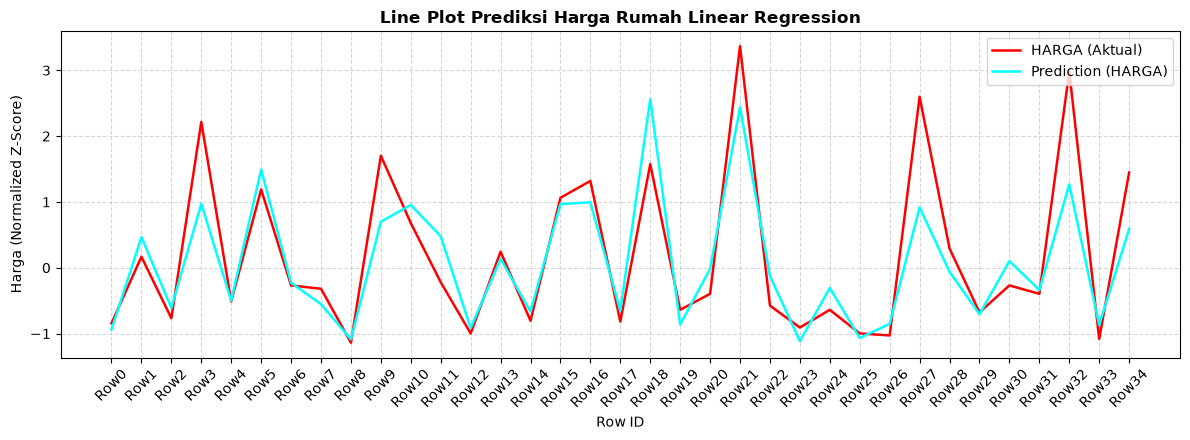

In [31]:
jumlah_plot = 35
x_labels = [f"Row{i}" for i in range(jumlah_plot)]

plt.figure(figsize=(12, 4.5))
plt.plot(x_labels, y_test.values[:jumlah_plot], color='red', linewidth=1.8, label='HARGA (Aktual)')
plt.plot(x_labels, y_pred_test_lr[:jumlah_plot], color='cyan', linewidth=1.8, label='Prediction (HARGA)')

plt.title('Line Plot Prediksi Harga Rumah Linear Regression', fontweight='bold')
plt.xlabel('Row ID')
plt.ylabel('Harga (Normalized Z-Score)')
plt.xticks(rotation=45)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Menyimpan Hasil Linear Regression

In [32]:
hasil_lr = {
    'Model': 'Linear Regression',
    'Training': metrik_train_lr,
    'Testing': metrik_test_lr,
    'y_test': y_test,
    'y_pred_test': y_pred_test_lr
}
joblib.dump(hasil_lr, 'hasil_lr.pkl')
print("Hasil Linear Regression berhasil disimpan ke 'model/hasil_lr.pkl'!")

Hasil Linear Regression berhasil disimpan ke 'model/hasil_lr.pkl'!
